<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/Lab02/pmp_tema1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tema 1 - laborator 2
**Simularea variabilelor aleatoare**

**Ex. 1.** Scrieţi un program în Python care să preia ca input un fişier .csv cu o listă oarecare şi să aibă ca output un număr
predeterminat de elemente din acea listă, fără repetiţie. Aplicaţi pe lista studenţilor din grupa dumneavoastră care nu
au prezentat încă o temă.

***Notă:** Pentru generarea unui eşantion aleator se poate apela funcţia sample din modulul random sau funcţia ran-
dom.choice cu argumentul replace=False din librăria Numpy.*

In [ ]:
continut = """Popescu Ion
Ionescu Ana
Stefanescu Alex
Georgescu Maria
Enescu Dragos
Mihai Radu"""

with open("studenti.csv", "w") as fisier:
    fisier.write(continut)

In [ ]:
import csv
import random

lista = []
with open("studenti.csv", "r") as fisier:
  cititor = csv.reader(fisier)
  for rand in cititor:
    lista.append(rand[0])

n = int(input("Cati studenti doriti sa alegeti? "))

alesi = random.sample(lista, n)

print("Studentii alesi sunt:")
for student in alesi:
  print(student)

Cati studenti doriti sa alegeti? 2
Studentii alesi sunt:
Stefanescu Alex
Enescu Dragos


**Ex. 2.** Doi prieteni joacă următorul joc, după următoarele reguli:

*Pasul 1. Primul jucător aruncă cu o monedă.*

*   Dacă pică stemă, cel de-al doilea trebuie să arunce cu zarul şi să-i dea primului o sumă egală z − 3 dolari, unde z
este rezultatul aruncării cu zarul (a da o sumă negativă este echivalent cu a lua opusul acelei sume). Jocul
se încheie aici.
*   Dacă pică ban, atunci primul jucător trebuie să-i dea celui de-al doilea 0.5 dolari.

*Pasul n. În caz că jocul nu s-a încheiat, se reia pasul 1.*

**a)** Ce fel de distribuţie urmează N, numărul de paşi ai jocului?

**b)** Simulaţi în Python un astfel de joc. Variabilele care ne interesează sunt N şi suma totală S pe care cel de-al doilea jucător trebuie să i-o dea primului.

**c)** Prin simularea unui număr mare de astfel de jocuri, determinaţi cu aproximaţie media lui S şi reprezentaţi grafic (printr-o histogramă) distribuţia acesteia.

**d)** Ce se întâmplă dacă moneda este măsluită? Încercaţi să refaceţi pct. c) cu o probabilitate de apariţie a stemei p = 0.3, respectiv p = 0.7.

a) La fiecare pas se arunca moneda: daca pica stema, jocul se opreste, iar daca pica ban, jocul continua si se reia pasul. Moneda fiind corecta, probabilitatea sa pice stema este egala cu probabilitatea sa pice ban (p=1/2).

Fie N numărul de pași ai jocului. Fie k un numar natural nenul.

Pentru ca jocul sa se opreasca exact la pasul k, trebuie sa pice ban la primii k-1 pasi (fiecare cu probabilitate 1/2) si stema la pasul k (probabilitate 1/2).

P(N=k) = (1/2)^(k-1)·(1/2) = (1/2)^k

Astfel, avand in vedere cele de mai sus, **N urmeaza o distributie geometrica de parametru p=1/2**.

In [ ]:
# b)

import random

def joc():
  N = 1
  S = 0

  moneda = random.randint(0, 1) # 0 = stema, 1 = ban

  while moneda == 1:
    S = S - 0.5
    N = N + 1
    moneda = random.randint(0, 1)

  zar = random.randint(1, 6)    # aruncam zarul
  S = S + (zar - 3)

  return N, S

N, S = joc()

print("Numarul de pasi, N =", N)
print("Suma primita de primul jucator, S =", S)

Numarul de pasi, N = 1
Suma primita de primul jucator, S = 2


Media lui S = -0.02955


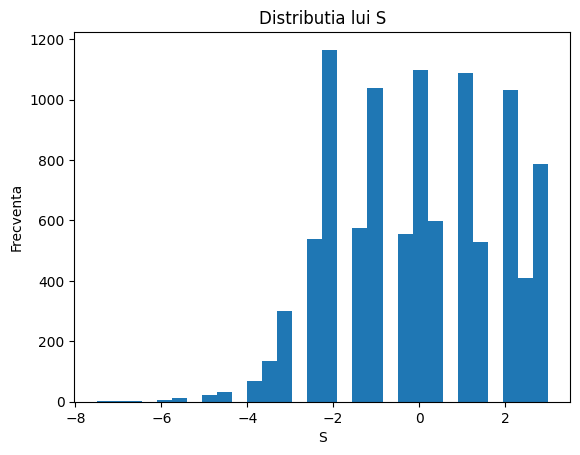

In [ ]:
# c)

import matplotlib.pyplot as plt

nr_jocuri = 10000
rezultate = []

for i in range(nr_jocuri):
  N, S = joc()
  rezultate.append(S)

media = sum(rezultate) / nr_jocuri
print("Media lui S =", media)

plt.hist(rezultate, bins=30)
plt.title("Distributia lui S")
plt.xlabel("S")
plt.ylabel("Frecventa")
plt.show()

p = 0.3  media lui S = -0.64515


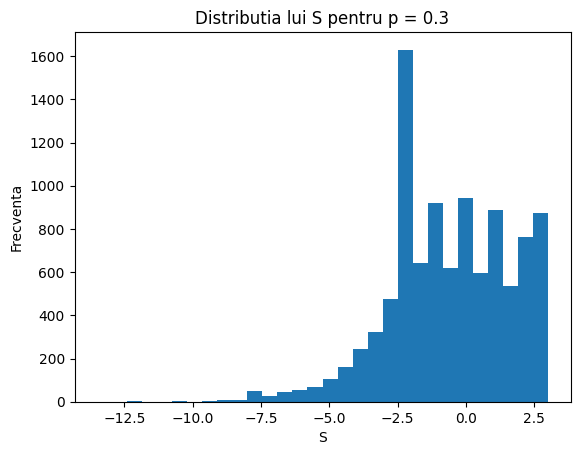

p = 0.7  media lui S = 0.28385


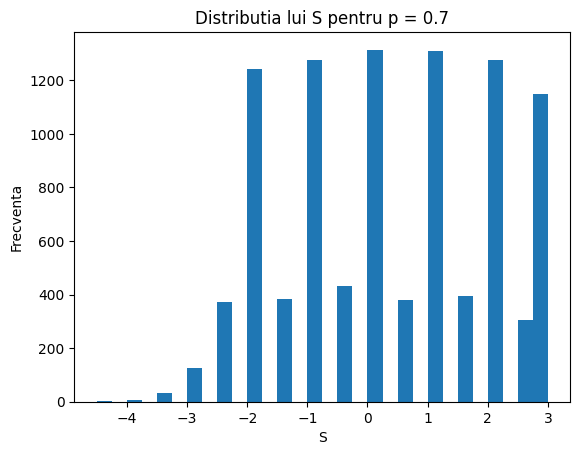

In [ ]:
# d)

import random
import matplotlib.pyplot as plt

def joc_masluit(p):
  N = 1
  S = 0

  moneda = random.random()

  while moneda >= p:
    S = S - 0.5
    N = N + 1
    moneda = random.random()

  zar = random.randint(1, 6)
  S = S + (zar - 3)

  return N, S

nr_jocuri = 10000

for p in [0.3, 0.7]:
  rezultate = []

  for i in range(nr_jocuri):
      N, S = joc_masluit(p)
      rezultate.append(S)

  media = sum(rezultate) / nr_jocuri
  print("p =", p, " media lui S =", media)

  plt.hist(rezultate, bins=30)
  plt.title("Distributia lui S pentru p = " + str(p))
  plt.xlabel("S")
  plt.ylabel("Frecventa")
  plt.show()

**Ex. 3.** Într-o frizerie, trei frizeri îşi tund clienţii cu următoarele viteze medii: primul cu 3 clienţi pe oră, al doilea cu 6 pe
oră iar al treilea cu 4 pe oră. Astfel, timpul de servire al unui client este modelat de distribuţii exponenţiale cu parametrii

λ1 = 3h^−1,

λ2 = 6h^−1,

respectiv λ3 = 4h^−1,

iar probabilităţile de preluare a unui client de către un anumit frizer sunt

3/13,

6/13,

respectiv 4/13 (de ce?).

Fie X timpul de servire pentru un client.
Generaţi 10000 de valori pentru X, şi în felul acesta estimaţi media şi deviaţia standard a lui X.

Realizaţi un grafic
aproximativ al densităţii distribuţiei lui X.

***Notă:** Distribuţia Exp(λ) se poate apela prin random.exponential(scale=1/λ) în Numpy, sau cu stats.expon(scale=1/λ)
în Scipy. Având în vedere că X are o distribuţie continuă, densitatea aproximativă acesteia se poate vizualiza folosind
funcţia plot_kde din librăria Arviz.*

**Rezolvare:** Frizerii servesc cu vitezele λ1=3, λ2=6, λ3=4 pe ora. Clientul este preluat de frizerul care se elibereaza primul.

Probabilitatea ca frizerul i sa fie primul eliberat este:

P(frizerul i este primul) = λi/(λ1+λ2+λ3)

Rezulta:

P(frizerul 1) = 3/13

P(frizerul 2) = 6/13

P(frizerul 3) = 4/13

Un frizer mai rapid, se elibereaza mai des, deci preia mai multi clienti.

Media lui X = 0.2312002091369583
Deviatia standard a lui X = 0.250955752076258


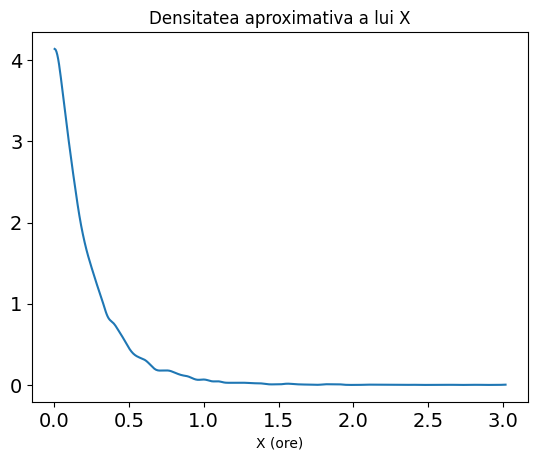

In [ ]:
import numpy as np
import arviz as az
import matplotlib.pyplot as plt

lambde = [3, 6, 4]
probabilitati = [3/13, 6/13, 4/13]

nr_valori = 10000
X = []

for i in range(nr_valori):
  lam = np.random.choice(lambde, p=probabilitati)
  x = np.random.exponential(scale=1/lam)
  X.append(x)

X = np.array(X)

print("Media lui X =", np.mean(X))
print("Deviatia standard a lui X =", np.std(X))

az.plot_kde(X)
plt.title("Densitatea aproximativa a lui X")
plt.xlabel("X (ore)")
plt.show()